# Notebook 01 — Auditoría y construcción de series SIDPOL

## Forecasting de denuncias de Robo y Hurto — Local vs. Global

**Objetivo:** validar el snapshot de SIDPOL y construir un panel mensual reproducible de:

`distrito × mes × target`

para los 43 distritos de la provincia de Lima, entre enero de 2018 y julio de 2026.

Esta notebook **no entrena modelos**. Su salida alimenta el Protocolo Metodológico.

### Decisiones de construcción

El CSV auditado es **positive-only**: no contiene filas con `cantidad = 0`. Por ello, una combinación `distrito-mes-target` ausente se reconstruye operacionalmente como cero y se conserva `value_origin`.


El diagnóstico de ceros **no elimina observaciones automáticamente**. Si el gate automático solicita revisión, los casos se inspeccionan y la decisión queda documentada.

> El target representa **denuncias registradas**. No se interpreta como criminalidad real, victimización ni totalidad de hechos delictivos ocurridos.


## 1. Configuración

La ruta se define una sola vez desde la carpeta raíz del proyecto.

Los resultados se guardarán en:

`MyDrive/Asesorias/Forecasting/01. Auditoria SIDPOL/`


In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/Asesorias/Forecasting")
DATA_PATH = PROJECT_DIR / "00. Datasets" / "DATASET_Denuncias_Policiales_Ene 2018 a Julio 2026.csv"
OUTPUT_DIR = PROJECT_DIR / "01. Auditoria SIDPOL"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = pd.Timestamp("2018-01-01")
END_DATE = pd.Timestamp("2026-07-01")
BREAK_DATE = pd.Timestamp("2024-11-01")
PRE_DESC_START = pd.Timestamp("2023-01-01")
PRE_DESC_END = pd.Timestamp("2024-10-01")
POST_DESC_START = pd.Timestamp("2024-11-01")
POST_DESC_END = pd.Timestamp("2026-07-01")
TARGETS = ["ROBO", "HURTO"]

EXPECTED_UBIGEOS = {f"1501{i:02d}" for i in range(1, 44)}
EXPECTED_COLUMNS = {
    "ANIO", "MES", "DPTO_HECHO_NEW", "PROV_HECHO",
    "DIST_HECHO", "UBIGEO_HECHO", "P_MODALIDADES", "cantidad"
}

print("Dataset :", DATA_PATH)
print("Salidas :", OUTPUT_DIR)


Mounted at /content/drive
Dataset : /content/drive/MyDrive/Asesorias/Forecasting/00. Datasets/DATASET_Denuncias_Policiales_Ene 2018 a Julio 2026.csv
Salidas : /content/drive/MyDrive/Asesorias/Forecasting/01. Auditoria SIDPOL


## 2. Funciones auxiliares

In [2]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def clean_ubigeo(series):
    return (
        series.astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.replace(r"\D", "", regex=True)
        .str.zfill(6)
    )


## 3. Carga y validaciones básicas

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, encoding="utf-8", low_memory=False)

print("Shape:", df.shape)
print("Columnas:", df.columns.tolist())

missing_columns = EXPECTED_COLUMNS - set(df.columns)
assert not missing_columns, f"Faltan columnas: {missing_columns}"

df["ANIO"] = pd.to_numeric(df["ANIO"], errors="raise")
df["MES"] = pd.to_numeric(df["MES"], errors="raise")
df["cantidad"] = pd.to_numeric(df["cantidad"], errors="raise")
df["UBIGEO"] = clean_ubigeo(df["UBIGEO_HECHO"])
df["MODALIDAD"] = df["P_MODALIDADES"].astype("string").str.strip().str.upper()

df["fecha"] = pd.to_datetime(
    dict(year=df["ANIO"], month=df["MES"], day=1)
)

print("Periodo:", df["fecha"].min().date(), "a", df["fecha"].max().date())
print("Meses:", df["fecha"].nunique())
print("Cantidad mínima:", df["cantidad"].min())
print("Cantidad máxima:", df["cantidad"].max())
print("Filas con cero:", int((df["cantidad"] == 0).sum()))
print("Filas negativas:", int((df["cantidad"] < 0).sum()))

assert df["fecha"].min() == START_DATE
assert df["fecha"].max() == END_DATE
assert df["fecha"].nunique() == 103
assert (df["cantidad"] > 0).all(), "El snapshot dejó de ser positive-only; revisar regla de ceros."


Shape: (369100, 8)
Columnas: ['ANIO', 'MES', 'DPTO_HECHO_NEW', 'PROV_HECHO', 'DIST_HECHO', 'UBIGEO_HECHO', 'P_MODALIDADES', 'cantidad']
Periodo: 2018-01-01 a 2026-07-01
Meses: 103
Cantidad mínima: 1
Cantidad máxima: 1303
Filas con cero: 0
Filas negativas: 0


### Lectura de la regla de ceros

En este snapshot todas las filas tienen `cantidad > 0`. Por tanto, el archivo no almacena filas explícitas para conteos cero.

Para construir una serie mensual completa:

- si existe la combinación `distrito-mes-target`, se utiliza `cantidad`;
- si no existe, se reconstruye `0`;
- se conserva `value_origin` para diferenciar valores observados de ceros reconstruidos.

Antes de aplicar la regla revisamos también si existen ausencias completas de un distrito-mes.


## 4. Lima Metropolitana: 43 distritos

In [4]:
df_lima = df[df["UBIGEO"].isin(EXPECTED_UBIGEOS)].copy()

observed_ubigeos = set(df_lima["UBIGEO"].unique())

print("Filas Lima:", len(df_lima))
print("Distritos observados:", len(observed_ubigeos))
print("UBIGEO faltantes:", sorted(EXPECTED_UBIGEOS - observed_ubigeos))

assert observed_ubigeos == EXPECTED_UBIGEOS

district_lookup = (
    df_lima[["UBIGEO", "DIST_HECHO"]]
    .drop_duplicates()
    .sort_values("UBIGEO")
)

# En Lima cada UBIGEO debe tener un único nombre en este snapshot.
assert district_lookup["UBIGEO"].nunique() == 43
assert len(district_lookup) == 43

display(district_lookup)


Filas Lima: 26527
Distritos observados: 43
UBIGEO faltantes: []


,UBIGEO,DIST_HECHO
1675,150101,LIMA
1591,150102,ANCON
1596,150103,ATE
1603,150104,BARRANCO
1609,150105,BREÑA
1614,150106,CARABAYLLO
1620,150107,CHACLACAYO
1625,150108,CHORRILLOS
1632,150109,CIENEGUILLA
1638,150110,COMAS


## 5. Modalidades y duplicados

In [5]:
modalities = (
    df_lima.groupby("MODALIDAD")["cantidad"]
    .agg(["size", "sum"])
    .sort_values("sum", ascending=False)
)

display(modalities)

for target in TARGETS:
    assert target in modalities.index

grain = ["ANIO", "MES", "UBIGEO", "MODALIDAD"]
n_duplicates = int(df_lima.duplicated(grain, keep=False).sum())

print("Filas involucradas en claves duplicadas:", n_duplicates)

# Aunque en Lima no se observaron duplicados, agregamos por suma para
# dejar una única fila por mes, distrito y modalidad.
monthly = (
    df_lima.groupby(
        ["fecha", "UBIGEO", "DIST_HECHO", "MODALIDAD"],
        as_index=False
    )["cantidad"].sum()
)


,size,sum
MODALIDAD,,
OTROS,4394,820649
VIOLENCIA CONTRA LA MUJER E INTEGRANTES,4386,695580
HURTO,4328,589906
ROBO,4190,350649
ESTAFA,4066,89964
EXTORSIÓN,3318,45313
SECUESTRO,1845,3612


Filas involucradas en claves duplicadas: 0


## 6. Ausencias completas de distrito-mes

In [6]:
months = pd.date_range(START_DATE, END_DATE, freq="MS")

district_month_grid = pd.MultiIndex.from_product(
    [sorted(EXPECTED_UBIGEOS), months],
    names=["UBIGEO", "fecha"]
).to_frame(index=False)

district_month_present = (
    monthly.groupby(["UBIGEO", "fecha"])
    .size()
    .rename("n_rows")
    .reset_index()
)

district_month_audit = district_month_grid.merge(
    district_month_present,
    on=["UBIGEO", "fecha"],
    how="left"
)

district_month_audit = district_month_audit.merge(
    district_lookup,
    on="UBIGEO",
    how="left"
)

no_rows = district_month_audit[
    district_month_audit["n_rows"].isna()
].copy()

print("Distrito-mes sin ninguna modalidad:", len(no_rows))
display(no_rows[["fecha", "UBIGEO", "DIST_HECHO"]].sort_values("fecha"))


Distrito-mes sin ninguna modalidad: 9


,fecha,UBIGEO,DIST_HECHO
3815,2018-05-01,150138,SANTA MARIA DEL MAR
3816,2018-06-01,150138,SANTA MARIA DEL MAR
3818,2018-08-01,150138,SANTA MARIA DEL MAR
3840,2020-06-01,150138,SANTA MARIA DEL MAR
3853,2021-07-01,150138,SANTA MARIA DEL MAR
3863,2022-05-01,150138,SANTA MARIA DEL MAR
3864,2022-06-01,150138,SANTA MARIA DEL MAR
3910,2026-04-01,150138,SANTA MARIA DEL MAR
3912,2026-06-01,150138,SANTA MARIA DEL MAR


**Interpretación:** la celda anterior muestra los distrito-mes sin ninguna modalidad en la **corrida actual**. En un snapshot positive-only, estos casos son compatibles con meses sin denuncias registradas en las modalidades publicadas, pero se conservan diferenciados mediante `value_origin="reconstructed_zero_no_rows"` para mantener trazabilidad.

## 7. Construcción del panel final

In [7]:
target_grid = pd.MultiIndex.from_product(
    [sorted(EXPECTED_UBIGEOS), months, TARGETS],
    names=["UBIGEO", "fecha", "target"]
).to_frame(index=False)

target_values = (
    monthly[monthly["MODALIDAD"].isin(TARGETS)]
    .rename(columns={"MODALIDAD": "target", "cantidad": "y_raw"})
    [["UBIGEO", "fecha", "target", "y_raw"]]
)

panel = (
    target_grid
    .merge(target_values, on=["UBIGEO", "fecha", "target"], how="left")
    .merge(district_lookup, on="UBIGEO", how="left")
)

# Distinguir un cero por target ausente de un mes sin ninguna fila del distrito.
no_rows_key = set(zip(no_rows["UBIGEO"], no_rows["fecha"]))

def value_origin(row):
    if pd.notna(row["y_raw"]):
        return "observed"
    if (row["UBIGEO"], row["fecha"]) in no_rows_key:
        return "reconstructed_zero_no_rows"
    return "reconstructed_zero_target_absent"

panel["value_origin"] = panel.apply(value_origin, axis=1)
panel["y"] = panel["y_raw"].fillna(0).astype(int)
panel["regime"] = np.where(
    panel["fecha"] < BREAK_DATE,
    "pre_break",
    "post_break"
)

panel = panel[
    ["fecha", "UBIGEO", "DIST_HECHO", "target", "y", "regime", "value_origin"]
].sort_values(["target", "UBIGEO", "fecha"]).reset_index(drop=True)

print("Filas del panel:", len(panel))
print("Valores faltantes:", int(panel["y"].isna().sum()))
display(panel.head())


Filas del panel: 8858
Valores faltantes: 0


,fecha,UBIGEO,DIST_HECHO,target,y,regime,value_origin
0,2018-01-01,150101,LIMA,HURTO,557,pre_break,observed
1,2018-02-01,150101,LIMA,HURTO,633,pre_break,observed
2,2018-03-01,150101,LIMA,HURTO,639,pre_break,observed
3,2018-04-01,150101,LIMA,HURTO,635,pre_break,observed
4,2018-05-01,150101,LIMA,HURTO,624,pre_break,observed


In [8]:
panel_summary = (
    panel.groupby(["target", "value_origin"])
    .size()
    .rename("n")
    .reset_index()
)

panel_summary["pct_target"] = (
    panel_summary["n"]
    / panel_summary.groupby("target")["n"].transform("sum")
    * 100
)

display(panel_summary)

assert len(panel) == 43 * 103 * 2
assert panel["y"].isna().sum() == 0
assert panel.groupby(["target", "UBIGEO"]).size().eq(103).all()


,target,value_origin,n,pct_target
0,HURTO,observed,4328,97.719576
1,HURTO,reconstructed_zero_no_rows,9,0.203206
2,HURTO,reconstructed_zero_target_absent,92,2.077218
3,ROBO,observed,4190,94.603748
4,ROBO,reconstructed_zero_no_rows,9,0.203206
5,ROBO,reconstructed_zero_target_absent,230,5.193046


### 7.1 Distribución de los ceros reconstruidos

La regla `ausencia → 0` se revisa en dos direcciones:

- **por distrito**, para verificar si los ceros se concentran principalmente en series de baja frecuencia;
- **por mes**, para detectar si aparecen concentraciones temporales compatibles con una pérdida de cobertura.

Este diagnóstico **no modifica ni excluye observaciones**. La sección 7.2 aplica un gate de revisión para identificar casos que requieren inspección antes de cerrar la auditoría.


Ceros reconstruidos por distrito (mayores valores):


,target,UBIGEO,DIST_HECHO,n_reconstructed_zero,pct_months
37,HURTO,150138,SANTA MARIA DEL MAR,64,62.135922
26,HURTO,150127,PUNTA NEGRA,16,15.533981
28,HURTO,150129,SAN BARTOLO,12,11.650485
23,HURTO,150124,PUCUSANA,4,3.883495
25,HURTO,150126,PUNTA HERMOSA,4,3.883495
3,HURTO,150104,BARRANCO,1,0.970874
0,HURTO,150101,LIMA,0,0.000000
1,HURTO,150102,ANCON,0,0.000000
2,HURTO,150103,ATE,0,0.000000
4,HURTO,150105,BREÑA,0,0.000000


Meses con más ceros reconstruidos:


,fecha,target,n_reconstructed_zero
59,2020-06-01,HURTO,5
55,2020-04-01,HURTO,3
61,2020-07-01,HURTO,3
65,2020-09-01,HURTO,3
69,2020-11-01,HURTO,3
79,2021-04-01,HURTO,3
85,2021-07-01,HURTO,3
9,2018-05-01,HURTO,2
31,2019-04-01,HURTO,2
35,2019-06-01,HURTO,2


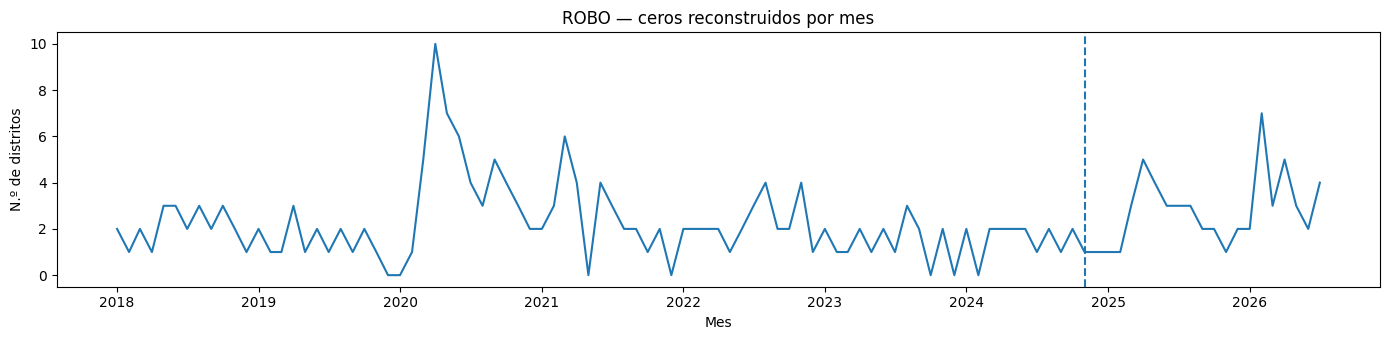

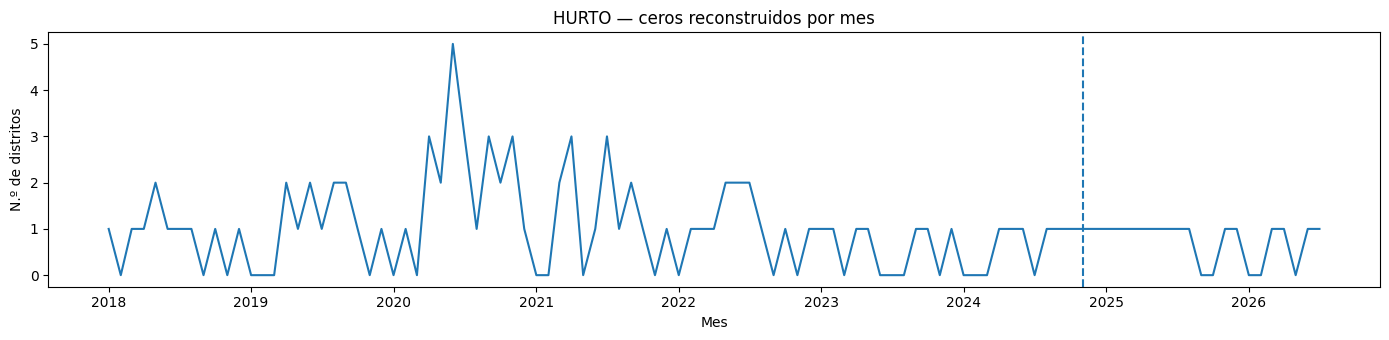

In [9]:
# Ceros reconstruidos disponibles en el panel final.
reconstructed_zeros = panel[panel["value_origin"] != "observed"].copy()

# Grillas completas para que los archivos incluyan también los casos con cero reconstrucciones.
series_grid = (
    panel[["target", "UBIGEO", "DIST_HECHO"]]
    .drop_duplicates()
    .sort_values(["target", "UBIGEO"])
)

zero_by_district = (
    reconstructed_zeros.groupby(["target", "UBIGEO", "DIST_HECHO"])
    .size()
    .rename("n_reconstructed_zero")
    .reset_index()
)

zero_by_district = series_grid.merge(
    zero_by_district,
    on=["target", "UBIGEO", "DIST_HECHO"],
    how="left",
)
zero_by_district["n_reconstructed_zero"] = (
    zero_by_district["n_reconstructed_zero"].fillna(0).astype(int)
)
zero_by_district["pct_months"] = zero_by_district["n_reconstructed_zero"] / 103 * 100

print("Ceros reconstruidos por distrito (mayores valores):")
display(
    zero_by_district
    .sort_values(["target", "n_reconstructed_zero"], ascending=[True, False])
    .groupby("target")
    .head(10)
)

month_target_grid = pd.MultiIndex.from_product(
    [months, TARGETS], names=["fecha", "target"]
).to_frame(index=False)

zero_by_month = (
    reconstructed_zeros.groupby(["fecha", "target"])
    .size()
    .rename("n_reconstructed_zero")
    .reset_index()
)

zero_by_month = month_target_grid.merge(
    zero_by_month,
    on=["fecha", "target"],
    how="left",
)
zero_by_month["n_reconstructed_zero"] = (
    zero_by_month["n_reconstructed_zero"].fillna(0).astype(int)
)

print("Meses con más ceros reconstruidos:")
display(
    zero_by_month
    .sort_values(["target", "n_reconstructed_zero"], ascending=[True, False])
    .groupby("target")
    .head(10)
)

for target in TARGETS:
    d = zero_by_month[zero_by_month["target"] == target]

    plt.figure(figsize=(14, 3.5))
    plt.plot(d["fecha"], d["n_reconstructed_zero"])
    plt.axvline(BREAK_DATE, linestyle="--")
    plt.title(f"{target} — ceros reconstruidos por mes")
    plt.xlabel("Mes")
    plt.ylabel("N.º de distritos")
    plt.tight_layout()
    plt.show()


### 7.2 Ceros reconstruidos a revisar

Como control adicional, un cero reconstruido se marca como **sospechoso** cuando la mediana de los 12 meses anteriores del mismo distrito-target es al menos 3.

Esta es una **regla operacional del estudio**, no un estándar externo. Además, `min_periods=12` implica que los primeros 12 meses de cada serie no pueden ser marcados por este diagnóstico.

La regla **no elimina ni modifica observaciones**. Solo identifica casos que requieren revisión.

Para evitar que el shock de 2020 distorsione el contraste, el gate utiliza las mismas ventanas homologables del diagnóstico descriptivo:

- pre-break: **2023-01→2024-10** (22 meses; 946 celdas por target);
- post-break: **2024-11→2026-07** (21 meses; 903 celdas por target).

El gate automático devuelve:

- `PASS` si la tasa post-break no supera la tasa pre-break en ninguno de los targets;
- `REVIEW_REQUIRED` si aumenta en al menos un target.

`REVIEW_REQUIRED` no implica que los datos sean inválidos: obliga a inspeccionar los casos post-break y documentar la decisión.


In [10]:
# El diagnóstico se calcula sobre una copia para no modificar el contrato del panel final.
diag = panel.sort_values(["target", "UBIGEO", "fecha"]).copy()

diag["median_prev12"] = (
    diag.groupby(["target", "UBIGEO"])["y"]
    .transform(lambda s: s.shift(1).rolling(12, min_periods=12).median())
)

reconstructed = diag[diag["value_origin"] != "observed"].copy()
reconstructed["suspicious_zero"] = reconstructed["median_prev12"] >= 3

suspicious_zeros = reconstructed[reconstructed["suspicious_zero"]].copy()

print("Ceros reconstruidos:", len(reconstructed))
print("Ceros sospechosos (mediana previa de 12 meses >= 3):", len(suspicious_zeros))

display(
    suspicious_zeros[
        ["fecha", "target", "UBIGEO", "DIST_HECHO", "median_prev12", "value_origin"]
    ].sort_values(["target", "fecha", "UBIGEO"])
)

# Ventanas homologables para el gate.
period_grid = pd.MultiIndex.from_product(
    [TARGETS, ["pre_break", "post_break"]],
    names=["target", "period"]
).to_frame(index=False)

window_panel = diag[
    diag["fecha"].between(PRE_DESC_START, POST_DESC_END)
].copy()

window_panel["period"] = np.select(
    [
        window_panel["fecha"].between(PRE_DESC_START, PRE_DESC_END),
        window_panel["fecha"].between(POST_DESC_START, POST_DESC_END),
    ],
    ["pre_break", "post_break"],
    default="outside"
)

window_panel = window_panel[window_panel["period"] != "outside"]

period_cells = (
    window_panel.groupby(["target", "period"])
    .size()
    .rename("n_cells")
    .reset_index()
)

suspicious_window = suspicious_zeros[
    suspicious_zeros["fecha"].between(PRE_DESC_START, POST_DESC_END)
].copy()

suspicious_window["period"] = np.select(
    [
        suspicious_window["fecha"].between(PRE_DESC_START, PRE_DESC_END),
        suspicious_window["fecha"].between(POST_DESC_START, POST_DESC_END),
    ],
    ["pre_break", "post_break"],
    default="outside"
)

suspicious_window = suspicious_window[suspicious_window["period"] != "outside"]

suspicious_counts = (
    suspicious_window.groupby(["target", "period"])
    .size()
    .rename("n_suspicious")
    .reset_index()
)

suspicious_rate = (
    period_grid
    .merge(period_cells, on=["target", "period"], how="left")
    .merge(suspicious_counts, on=["target", "period"], how="left")
)

suspicious_rate["n_suspicious"] = suspicious_rate["n_suspicious"].fillna(0).astype(int)
suspicious_rate["rate_pct"] = (
    suspicious_rate["n_suspicious"] / suspicious_rate["n_cells"] * 100
)

display(suspicious_rate)

rate_pivot = suspicious_rate.pivot(
    index="target",
    columns="period",
    values="rate_pct"
)

ZERO_AUTO_PASS = bool(
    (rate_pivot["post_break"] <= rate_pivot["pre_break"]).all()
)

ZERO_AUTO_STATUS = "PASS" if ZERO_AUTO_PASS else "REVIEW_REQUIRED"
print("ZERO_AUTO_STATUS:", ZERO_AUTO_STATUS)

# Casos que deben revisarse cuando el gate automático solicita revisión.
post_suspicious = suspicious_window[
    suspicious_window["period"] == "post_break"
].copy()

print("Casos sospechosos post-break a revisar:", len(post_suspicious))
display(
    post_suspicious[
        ["fecha", "target", "UBIGEO", "DIST_HECHO", "median_prev12", "value_origin"]
    ].sort_values(["target", "fecha", "UBIGEO"])
)


Ceros reconstruidos: 340
Ceros sospechosos (mediana previa de 12 meses >= 3): 42


,fecha,target,UBIGEO,DIST_HECHO,median_prev12,value_origin
2899,2019-04-01,HURTO,150129,SAN BARTOLO,3.0,reconstructed_zero_target_absent
2901,2019-06-01,HURTO,150129,SAN BARTOLO,3.0,reconstructed_zero_target_absent
2697,2019-08-01,HURTO,150127,PUNTA NEGRA,8.5,reconstructed_zero_target_absent
2698,2019-09-01,HURTO,150127,PUNTA NEGRA,8.0,reconstructed_zero_target_absent
2699,2019-10-01,HURTO,150127,PUNTA NEGRA,7.5,reconstructed_zero_target_absent
2602,2020-04-01,HURTO,150126,PUNTA HERMOSA,6.0,reconstructed_zero_target_absent
2603,2020-05-01,HURTO,150126,PUNTA HERMOSA,6.0,reconstructed_zero_target_absent
338,2020-06-01,HURTO,150104,BARRANCO,71.5,reconstructed_zero_target_absent
2398,2020-06-01,HURTO,150124,PUCUSANA,7.0,reconstructed_zero_target_absent
2913,2020-06-01,HURTO,150129,SAN BARTOLO,3.0,reconstructed_zero_target_absent


,target,period,n_cells,n_suspicious,rate_pct
0,ROBO,pre_break,946,3,0.317125
1,ROBO,post_break,903,5,0.553710
2,HURTO,pre_break,946,1,0.105708
3,HURTO,post_break,903,1,0.110742


ZERO_AUTO_STATUS: REVIEW_REQUIRED
Casos sospechosos post-break a revisar: 6


,fecha,target,UBIGEO,DIST_HECHO,median_prev12,value_origin
2664,2025-06-01,HURTO,150126,PUNTA HERMOSA,5.0,reconstructed_zero_target_absent
6472,2025-03-01,ROBO,150120,MAGDALENA DEL MAR,12.0,reconstructed_zero_target_absent
5340,2025-04-01,ROBO,150109,CIENEGUILLA,4.0,reconstructed_zero_target_absent
6473,2025-04-01,ROBO,150120,MAGDALENA DEL MAR,12.0,reconstructed_zero_target_absent
5342,2025-06-01,ROBO,150109,CIENEGUILLA,3.0,reconstructed_zero_target_absent
6483,2026-02-01,ROBO,150120,MAGDALENA DEL MAR,3.5,reconstructed_zero_target_absent


#### Revisión manual del gate de ceros — snapshot enero 2018 a julio 2026

Con las ventanas homologables, el gate automático devuelve `REVIEW_REQUIRED`. La revisión se limita a los **seis casos post-break** identificados por la regla:

- **Robo — Magdalena del Mar:** 2025-03, 2025-04 y 2026-02;
- **Robo — Cieneguilla:** 2025-04 y 2025-06;
- **Hurto — Punta Hermosa:** 2025-06.

La mediana móvil de 12 meses cruza el cambio de régimen de noviembre de 2024, por lo que durante los primeros meses post-break todavía incorpora observaciones del régimen anterior. Los seis flags se concentran en tres distritos y son **consistentes con el cambio de nivel observado**, sin mostrar un patrón generalizado de pérdida de cobertura.

**Decisión documentada:** mantener los seis valores como ceros reconstruidos, conservar `value_origin` y cerrar la revisión manual. No se crea una regla adicional consciente del régimen, porque no aportaría evidencia proporcional a su complejidad.

Si en una futura versión del snapshot cambia el conjunto de seis casos, esta revisión debe repetirse.


In [11]:
# Verificación reproducible de que la corrida actual corresponde a los seis casos revisados.
expected_post_review = {
    ("ROBO", "150120", "2025-03-01"),
    ("ROBO", "150120", "2025-04-01"),
    ("ROBO", "150120", "2026-02-01"),
    ("ROBO", "150109", "2025-04-01"),
    ("ROBO", "150109", "2025-06-01"),
    ("HURTO", "150126", "2025-06-01"),
}

observed_post_review = {
    (row.target, row.UBIGEO, row.fecha.strftime("%Y-%m-%d"))
    for row in post_suspicious.itertuples(index=False)
}

ZERO_MANUAL_REVIEW_RESOLVED = observed_post_review == expected_post_review

print("Revisión manual reproducible:", ZERO_MANUAL_REVIEW_RESOLVED)

if not ZERO_MANUAL_REVIEW_RESOLVED:
    print(
        "REVIEW_REQUIRED — el conjunto de casos post-break cambió; "
        "repetir la revisión manual antes de cerrar la auditoría."
    )


Revisión manual reproducible: True


## 8. Diagnóstico descriptivo de las 86 series

In [12]:
group_cols = ["target", "UBIGEO", "DIST_HECHO"]

series_summary = (
    panel.groupby(group_cols)["y"]
    .agg(
        n_months="size",
        n_zero=lambda s: int((s == 0).sum()),
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max",
    )
    .reset_index()
)

series_summary["pct_zero"] = series_summary["n_zero"] / series_summary["n_months"] * 100

pre_means = (
    panel[panel["fecha"].between(PRE_DESC_START, PRE_DESC_END)]
    .groupby(group_cols)["y"]
    .mean()
    .rename("pre_mean_2023_2024_10")
    .reset_index()
)

post_means = (
    panel[panel["fecha"].between(POST_DESC_START, POST_DESC_END)]
    .groupby(group_cols)["y"]
    .mean()
    .rename("post_mean_2024_11_2026_07")
    .reset_index()
)

series_summary = (
    series_summary
    .merge(pre_means, on=group_cols, how="left")
    .merge(post_means, on=group_cols, how="left")
)

series_summary["post_pre_ratio"] = (
    series_summary["post_mean_2024_11_2026_07"]
    / series_summary["pre_mean_2023_2024_10"].replace(0, np.nan)
)

print("Series:", len(series_summary))
display(
    series_summary
    .sort_values(["target", "pct_zero"], ascending=[True, False])
    .groupby("target")
    .head(10)
)

assert len(series_summary) == 86
assert series_summary["n_months"].eq(103).all()


ratio_summary = (
    series_summary.groupby("target")["post_pre_ratio"]
    .agg(
        median_ratio="median",
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
    )
    .reset_index()
)

print("Distribución completa del cambio post/pre por target:")
display(ratio_summary)


Series: 86


,target,UBIGEO,DIST_HECHO,n_months,n_zero,mean,median,std,min,max,pct_zero,pre_mean_2023_2024_10,post_mean_2024_11_2026_07,post_pre_ratio
37,HURTO,150138,SANTA MARIA DEL MAR,103,64,0.718447,0.0,1.705915,0,15,62.135922,1.318182,0.380952,0.288998
26,HURTO,150127,PUNTA NEGRA,103,16,4.019417,4.0,3.366445,0,14,15.533981,4.818182,3.619048,0.751123
28,HURTO,150129,SAN BARTOLO,103,12,4.038835,3.0,3.083550,0,12,11.650485,6.045455,6.047619,1.000358
23,HURTO,150124,PUCUSANA,103,4,7.135922,7.0,4.256595,0,19,3.883495,11.000000,8.428571,0.766234
25,HURTO,150126,PUNTA HERMOSA,103,4,7.495146,6.0,5.912555,0,30,3.883495,9.363636,7.285714,0.778086
3,HURTO,150104,BARRANCO,103,1,70.708738,78.0,32.711943,0,129,0.970874,98.227273,86.619048,0.881823
0,HURTO,150101,LIMA,103,0,641.776699,652.0,222.065391,62,1113,0.000000,883.909091,804.000000,0.909596
1,HURTO,150102,ANCON,103,0,23.563107,23.0,9.759530,5,54,0.000000,34.363636,21.095238,0.613883
2,HURTO,150103,ATE,103,0,266.252427,269.0,72.871862,45,476,0.000000,342.909091,299.333333,0.872923
4,HURTO,150105,BREÑA,103,0,104.029126,104.0,35.634709,11,170,0.000000,136.681818,135.285714,0.989786


Distribución completa del cambio post/pre por target:


,target,median_ratio,q1,q3
0,HURTO,0.813826,0.684127,0.883316
1,ROBO,0.422585,0.349739,0.487260


Los descriptivos del cambio de régimen comparan ventanas casi simétricas: **2023-01→2024-10 (22 meses)** frente a **2024-11→2026-07 (21 meses)**. Esto evita que la comparación `pre/post` quede dominada por años mucho más antiguos o por el shock de 2020. Sigue siendo un análisis descriptivo, no causal.

## 9. Visualización temporal

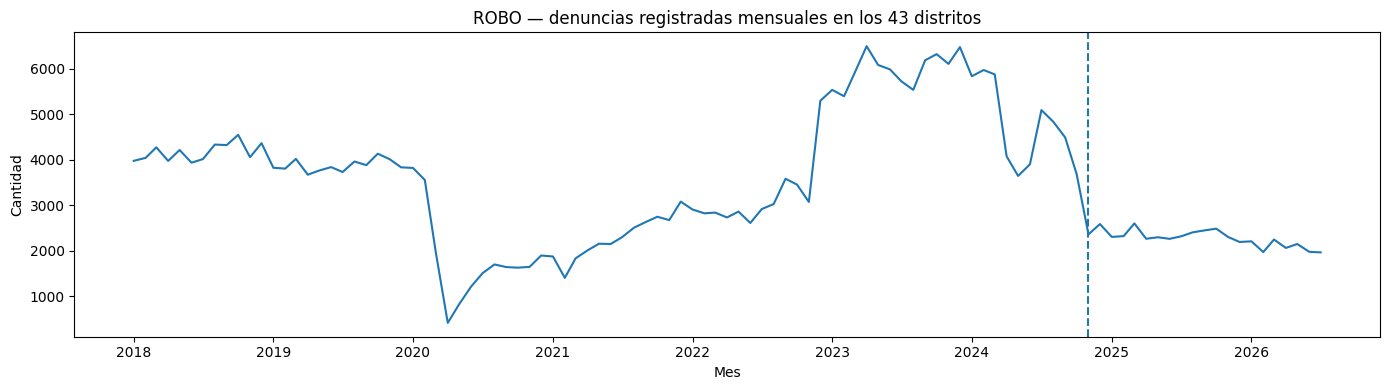

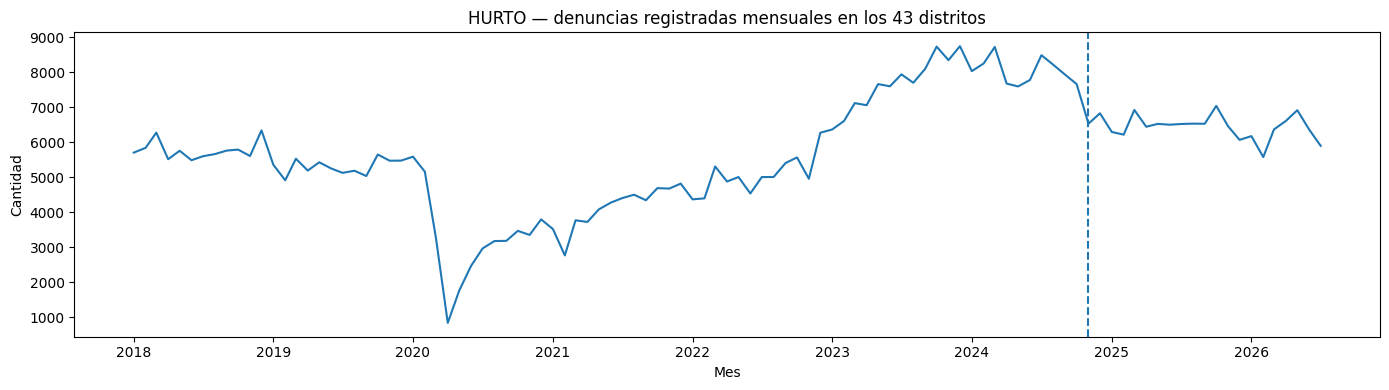

In [13]:
monthly_total = (
    panel.groupby(["fecha", "target"], as_index=False)["y"].sum()
)

for target in TARGETS:
    d = monthly_total[monthly_total["target"] == target]

    plt.figure(figsize=(14, 4))
    plt.plot(d["fecha"], d["y"])
    plt.axvline(BREAK_DATE, linestyle="--")
    plt.title(f"{target} — denuncias registradas mensuales en los 43 distritos")
    plt.xlabel("Mes")
    plt.ylabel("Cantidad")
    plt.tight_layout()
    plt.show()


## 10. Constantes MASE y control externo de agregación

### 10.1 Constantes de MASE

El denominador de MASE se fija una sola vez por `distrito × target` usando la ventana **2018-01→2022-12**.

Con 60 meses y estacionalidad 12, cada serie dispone de **48 diferencias interanuales**.

La auditoría comprueba que los 86 valores sean mayores que cero. El denominador usado posteriormente en la **calibración interna** del experimento se recalculará solo con la ventana disponible en ese proceso; en su primer origen habrá 48 meses y, por tanto, **36 diferencias interanuales**.

### 10.2 Contraste externo con el mismo corte temporal

Para detectar errores silenciosos de agregación, se comparan los totales del panel con el reporte oficial **“Denuncias registradas en el SIDPOL a julio 2026”**, cuyas cifras están actualizadas al **31/07/2026**.

Se utilizan exactamente los periodos **enero-julio de 2025 y enero-julio de 2026** para Lima Metropolitana:

| Target | Ene.-jul. 2025 | Ene.-jul. 2026 |
|---|---:|---:|
| Robo | 16,359 | 14,569 |
| Hurto | 45,422 | 43,903 |

Fuente: Observatorio Nacional de Seguridad Ciudadana — MININTER, Reporte SIDPOL julio 2026.

https://observatorio.mininter.gob.pe/sites/default/files/proyecto/archivos/Reporte_SIDPOL_Julio2026.pdf

Al tratarse del mismo sistema, ámbito geográfico y fecha de corte, una diferencia distinta de cero se envía a revisión antes de cerrar la auditoría.


In [14]:
REFERENCE_END = pd.Timestamp("2022-12-01")

reference = panel[panel["fecha"] <= REFERENCE_END].copy()

mase_constants = []
for (target, ubigeo, distrito), g in reference.groupby(
    ["target", "UBIGEO", "DIST_HECHO"]
):
    g = g.sort_values("fecha")
    y = g["y"].to_numpy(dtype=float)
    diffs = np.abs(y[12:] - y[:-12])

    mase_constants.append({
        "target": target,
        "UBIGEO": ubigeo,
        "DIST_HECHO": distrito,
        "n_reference_months": len(y),
        "n_mase_differences": len(diffs),
        "Q_j": float(diffs.mean()),
    })

mase_constants = pd.DataFrame(mase_constants)

print("Series con Q_j <= 0:", int((mase_constants["Q_j"] <= 0).sum()))
print("Q_j mínimo:", mase_constants["Q_j"].min())
print("Q_j máximo:", mase_constants["Q_j"].max())

display(mase_constants.sort_values("Q_j").head(10))

assert len(mase_constants) == 86
assert mase_constants["n_reference_months"].eq(60).all()
assert mase_constants["n_mase_differences"].eq(48).all()


# ------------------------------------------------------------------
# Contraste externo: mismo corte temporal que el snapshot (31/07/2026)
# ------------------------------------------------------------------
official_reference = pd.DataFrame([
    {
        "period": "2025-01_to_2025-07",
        "start": pd.Timestamp("2025-01-01"),
        "end": pd.Timestamp("2025-07-01"),
        "target": "ROBO",
        "official_total": 16359,
    },
    {
        "period": "2026-01_to_2026-07",
        "start": pd.Timestamp("2026-01-01"),
        "end": pd.Timestamp("2026-07-01"),
        "target": "ROBO",
        "official_total": 14569,
    },
    {
        "period": "2025-01_to_2025-07",
        "start": pd.Timestamp("2025-01-01"),
        "end": pd.Timestamp("2025-07-01"),
        "target": "HURTO",
        "official_total": 45422,
    },
    {
        "period": "2026-01_to_2026-07",
        "start": pd.Timestamp("2026-01-01"),
        "end": pd.Timestamp("2026-07-01"),
        "target": "HURTO",
        "official_total": 43903,
    },
])

checks = []

for row in official_reference.itertuples(index=False):
    panel_total = int(
        panel.loc[
            (panel["target"] == row.target)
            & panel["fecha"].between(row.start, row.end),
            "y"
        ].sum()
    )

    checks.append({
        "period": row.period,
        "target": row.target,
        "official_total": int(row.official_total),
        "panel_total": panel_total,
    })

external_check = pd.DataFrame(checks)
external_check["difference"] = (
    external_check["panel_total"] - external_check["official_total"]
)
external_check["difference_pct"] = (
    external_check["difference"]
    / external_check["official_total"]
    * 100
)
external_check["exact_match"] = external_check["difference"].eq(0)

display(external_check)

EXTERNAL_CHECK_PASS = bool(external_check["exact_match"].all())

if EXTERNAL_CHECK_PASS:
    print("PASS — los cuatro agregados coinciden exactamente con el reporte oficial.")
else:
    print(
        "REVIEW_REQUIRED — existe al menos una diferencia frente al "
        "reporte oficial con el mismo corte temporal."
    )


Series con Q_j <= 0: 0
Q_j mínimo: 0.5416666666666666
Q_j máximo: 171.0


,target,UBIGEO,DIST_HECHO,n_reference_months,n_mase_differences,Q_j
80,ROBO,150138,SANTA MARIA DEL MAR,60,48,0.541667
37,HURTO,150138,SANTA MARIA DEL MAR,60,48,0.791667
68,ROBO,150126,PUNTA HERMOSA,60,48,1.666667
71,ROBO,150129,SAN BARTOLO,60,48,1.687500
51,ROBO,150109,CIENEGUILLA,60,48,1.895833
69,ROBO,150127,PUNTA NEGRA,60,48,1.937500
66,ROBO,150124,PUCUSANA,60,48,1.958333
28,HURTO,150129,SAN BARTOLO,60,48,2.145833
81,ROBO,150139,SANTA ROSA,60,48,2.208333
26,HURTO,150127,PUNTA NEGRA,60,48,2.833333


,period,target,official_total,panel_total,difference,difference_pct,exact_match
0,2025-01_to_2025-07,ROBO,16359,16359,0,0.0,True
1,2026-01_to_2026-07,ROBO,14569,14569,0,0.0,True
2,2025-01_to_2025-07,HURTO,45422,45422,0,0.0,True
3,2026-01_to_2026-07,HURTO,43903,43903,0,0.0,True


PASS — los cuatro agregados coinciden exactamente con el reporte oficial.


## 11. Exportación reproducible

In [15]:
file_hash = sha256_file(DATA_PATH)

metadata = {
    "filename": DATA_PATH.name,
    "sha256": file_hash,
    "period_start": str(START_DATE.date()),
    "period_end": str(END_DATE.date()),
    "break_date": str(BREAK_DATE.date()),
    "n_raw_rows": int(len(df)),
    "n_lima_rows": int(len(df_lima)),
    "n_districts": 43,
    "n_months": 103,
    "n_targets": 2,
    "n_series": 86,
    "n_panel_rows": int(len(panel)),
    "n_duplicate_rows_lima": n_duplicates,
    "n_district_month_no_rows": int(len(no_rows)),
    "n_reconstructed_zero_cells": int((panel["value_origin"] != "observed").sum()),
    "n_suspicious_zero_cells": int(len(suspicious_zeros)),
    "zero_rule": (
        "Absent district-month-target combinations are reconstructed as zero "
        "because the audited snapshot is positive-only."
    ),
    "suspicious_zero_rule": (
        "A reconstructed zero is flagged when the previous-12-month median "
        "for the same district-target is >= 3; this is an operational study rule."
    ),
    "suspicious_zero_min_periods": 12,
    "suspicious_zero_gate_window_pre": "2023-01 to 2024-10",
    "suspicious_zero_gate_window_post": "2024-11 to 2026-07",
    "zero_auto_status": ZERO_AUTO_STATUS,
    "zero_manual_review_resolved": bool(ZERO_MANUAL_REVIEW_RESOLVED),
    "pre_descriptive_window": "2023-01 to 2024-10",
    "post_descriptive_window": "2024-11 to 2026-07",
    "mase_reference_window": "2018-01 to 2022-12",
    "external_reference": (
        "MININTER Observatorio Nacional de Seguridad Ciudadana, "
        "Reporte SIDPOL julio 2026, cifras actualizadas al 31/07/2026."
    ),
    "external_check_exact_match": bool(EXTERNAL_CHECK_PASS),
    "environment": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
    },
}

# El panel contractual se exporta sin columnas diagnósticas temporales.
PANEL_COLUMNS = [
    "fecha", "UBIGEO", "DIST_HECHO", "target", "y", "regime", "value_origin"
]
assert list(panel.columns) == PANEL_COLUMNS

panel.to_csv(
    OUTPUT_DIR / "sidpol_panel_lima_robo_hurto.csv",
    index=False
)
series_summary.to_csv(
    OUTPUT_DIR / "sidpol_series_summary.csv",
    index=False
)
no_rows[["fecha", "UBIGEO", "DIST_HECHO"]].to_csv(
    OUTPUT_DIR / "sidpol_district_month_no_rows.csv",
    index=False
)
zero_by_district.to_csv(
    OUTPUT_DIR / "sidpol_reconstructed_zeros_by_district.csv",
    index=False
)
zero_by_month.to_csv(
    OUTPUT_DIR / "sidpol_reconstructed_zeros_by_month.csv",
    index=False
)
suspicious_zeros.to_csv(
    OUTPUT_DIR / "sidpol_suspicious_reconstructed_zeros.csv",
    index=False
)
post_suspicious.to_csv(
    OUTPUT_DIR / "sidpol_suspicious_zeros_postbreak_manual_review.csv",
    index=False
)
mase_constants.to_csv(
    OUTPUT_DIR / "sidpol_mase_constants.csv",
    index=False
)
external_check.to_csv(
    OUTPUT_DIR / "sidpol_external_aggregation_check.csv",
    index=False
)

with open(
    OUTPUT_DIR / "sidpol_snapshot_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Archivos guardados en:", OUTPUT_DIR)
for name in [
    "sidpol_panel_lima_robo_hurto.csv",
    "sidpol_series_summary.csv",
    "sidpol_district_month_no_rows.csv",
    "sidpol_reconstructed_zeros_by_district.csv",
    "sidpol_reconstructed_zeros_by_month.csv",
    "sidpol_suspicious_reconstructed_zeros.csv",
    "sidpol_suspicious_zeros_postbreak_manual_review.csv",
    "sidpol_mase_constants.csv",
    "sidpol_external_aggregation_check.csv",
    "sidpol_snapshot_metadata.json",
]:
    print("-", name)


Archivos guardados en: /content/drive/MyDrive/Asesorias/Forecasting/01. Auditoria SIDPOL
- sidpol_panel_lima_robo_hurto.csv
- sidpol_series_summary.csv
- sidpol_district_month_no_rows.csv
- sidpol_reconstructed_zeros_by_district.csv
- sidpol_reconstructed_zeros_by_month.csv
- sidpol_suspicious_reconstructed_zeros.csv
- sidpol_suspicious_zeros_postbreak_manual_review.csv
- sidpol_mase_constants.csv
- sidpol_external_aggregation_check.csv
- sidpol_snapshot_metadata.json


## 12. Cierre de auditoría

El cierre utiliza cuatro controles:

1. **Integridad estructural:** 43 distritos, 103 meses, 86 series, 8,858 celdas, sin `y` faltantes ni duplicados.
2. **Gate automático de ceros:** compara las ventanas homologables 2023-01→2024-10 y 2024-11→2026-07.
3. **Revisión manual de ceros:** si el gate automático devuelve `REVIEW_REQUIRED`, el conjunto de casos post-break debe coincidir con los seis casos revisados y documentados para este snapshot.
4. **Consistencia externa:** los cuatro agregados enero-julio deben coincidir con el reporte MININTER de julio de 2026.

El resultado puede ser:

- `FAIL`: problema estructural del panel o MASE no calculable;
- `REVIEW_REQUIRED`: cambió el patrón de ceros revisado o falló el contraste externo;
- `READY_FOR_PROTOCOL`: los controles estructurales y externos pasan y, cuando corresponde, la revisión manual está documentada.


In [16]:
final_summary = pd.Series({
    "snapshot_sha256": file_hash,
    "period": "2018-01 a 2026-07",
    "districts": panel["UBIGEO"].nunique(),
    "months": panel["fecha"].nunique(),
    "targets": ", ".join(TARGETS),
    "series": panel.groupby(["target", "UBIGEO"]).ngroups,
    "panel_rows": len(panel),
    "missing_y": panel["y"].isna().sum(),
    "duplicate_rows_lima": n_duplicates,
    "district_month_no_rows": len(no_rows),
    "reconstructed_zero_cells": int(
        (panel["value_origin"] != "observed").sum()
    ),
    "suspicious_zero_cells": len(suspicious_zeros),
    "zero_auto_status": ZERO_AUTO_STATUS,
    "zero_manual_review_resolved": ZERO_MANUAL_REVIEW_RESOLVED,
    "external_check_pass": EXTERNAL_CHECK_PASS,
    "mase_q_nonpositive": int(
        (mase_constants["Q_j"] <= 0).sum()
    ),
    "pre_descriptive_months": panel.loc[
        panel["fecha"].between(PRE_DESC_START, PRE_DESC_END),
        "fecha"
    ].nunique(),
    "post_descriptive_months": panel.loc[
        panel["fecha"].between(POST_DESC_START, POST_DESC_END),
        "fecha"
    ].nunique(),
})

display(final_summary)

base_checks = [
    final_summary["districts"] == 43,
    final_summary["months"] == 103,
    final_summary["series"] == 86,
    final_summary["panel_rows"] == 8858,
    final_summary["missing_y"] == 0,
    final_summary["duplicate_rows_lima"] == 0,
    final_summary["pre_descriptive_months"] == 22,
    final_summary["post_descriptive_months"] == 21,
    final_summary["mase_q_nonpositive"] == 0,
]

if not all(base_checks):
    AUDIT_STATUS = "FAIL — corregir integridad del panel antes de continuar"
elif not EXTERNAL_CHECK_PASS:
    AUDIT_STATUS = "REVIEW_REQUIRED — revisar contraste externo de agregación"
elif ZERO_AUTO_STATUS == "REVIEW_REQUIRED" and not ZERO_MANUAL_REVIEW_RESOLVED:
    AUDIT_STATUS = "REVIEW_REQUIRED — repetir revisión manual del patrón de ceros"
else:
    AUDIT_STATUS = "READY_FOR_PROTOCOL — auditoría cerrada"

print("\nAUDIT_STATUS:", AUDIT_STATUS)


,0
snapshot_sha256,baf9b11a2496d2c675326e7265ad0d9b5464b261dd2b73...
period,2018-01 a 2026-07
districts,43
months,103
targets,"ROBO, HURTO"
series,86
panel_rows,8858
missing_y,0
duplicate_rows_lima,0
district_month_no_rows,9



AUDIT_STATUS: READY_FOR_PROTOCOL — auditoría cerrada
